<a href="https://colab.research.google.com/github/KRISHNA-EP18/Machine_Learning_IMLE/blob/main/CNN_tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Importing Libraries

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import classification_report

In [ ]:
print("PyTorch version:", torch.__version__)

PyTorch version: 2.14.1+cpu


In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cpu


In [ ]:
x = torch.tensor([[1, 2], [3, 4],[5,6]])

In [ ]:
x*2

tensor([[ 2,  4],
        [ 6,  8],
        [10, 12]])

In [ ]:
x.shape

torch.Size([3, 2])

In [ ]:
k=torch.tensor([1,2])

In [ ]:
k.shape

torch.Size([2])

In [ ]:
x

tensor([[1, 2],
        [3, 4],
        [5, 6]])

In [ ]:
x*k

tensor([[ 1,  4],
        [ 3,  8],
        [ 5, 12]])

In [ ]:
transform = transforms.ToTensor()

In [ ]:
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:01<00:00, 6.78MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 159kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.14MB/s]


In [ ]:
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [ ]:
print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Training samples: 60000
Test samples: 10000


In [ ]:
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)

Image shape: torch.Size([1, 28, 28])
Label: 5


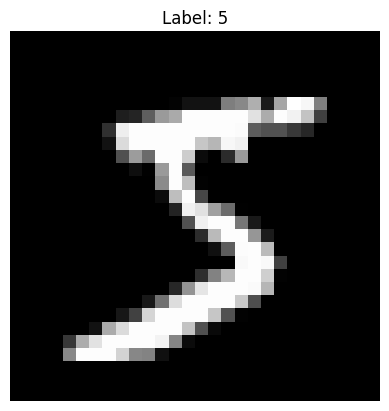

In [ ]:
plt.imshow(image.squeeze(), cmap="gray") #squeeze removes 1 dimension
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

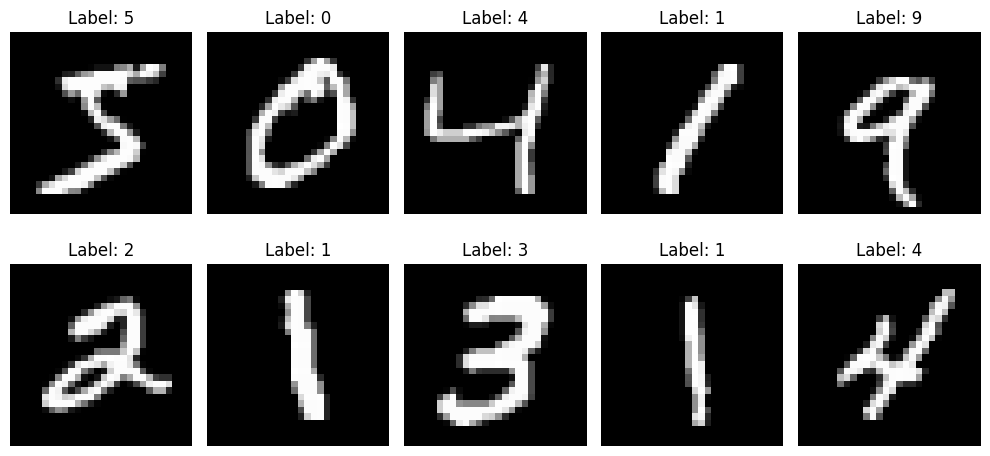

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(10, 5))

for i, ax in enumerate(axes.flat):

    image, label = train_dataset[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Label: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
batch_size = 64

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

In [ ]:
test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [ ]:
images, labels = next(iter(train_loader))

In [ ]:
print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])


In [ ]:
print(labels)

tensor([8, 0, 9, 2, 8, 8, 9, 6, 3, 0, 7, 8, 1, 8, 1, 9, 3, 9, 0, 4, 6, 0, 0, 2,
        0, 7, 9, 6, 4, 1, 7, 4, 9, 6, 2, 1, 5, 7, 4, 8, 1, 6, 7, 2, 5, 1, 7, 8,
        6, 2, 1, 8, 9, 2, 3, 4, 3, 5, 1, 0, 3, 2, 8, 2])


In [ ]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Convolutional layers for feature extraction
        self.features = nn.Sequential(
            # Block 1: Input (1, 28, 28) -> Output (16, 14, 14)
            nn.Conv2d(in_channels=1, out_channels=16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Block 2: Input (16, 14, 14) -> Output (32, 7, 7)
            nn.Conv2d(in_channels=16, out_channels=32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2)
        )

        self.flatten = nn.Flatten()

        # Fully connected layers for classification
        self.classifier = nn.Sequential(
            nn.Linear(32 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.flatten(x)
        x = self.classifier(x)
        return x

# CNN Architecture – MNIST

**Input:** 64 images | 1 channel | 28 × 28 pixels

                 INPUT
          ┌───────────────────┐
          │   64 × 1 × 28 × 28 │
          └───────────────────┘
                    │
                    ▼
       ┌──────────────────────────┐
       │    CONVOLUTION BLOCK 1   │
       │                          │
       │  Conv2D: 1 → 16          │
       │  BatchNorm + ReLU        │
       │  MaxPool: 2 × 2          │
       └──────────────────────────┘
                    │
                    ▼
          64 × 16 × 14 × 14
                    │
                    ▼
       ┌──────────────────────────┐
       │    CONVOLUTION BLOCK 2   │
       │                          │
       │  Conv2D: 16 → 32         │
       │  BatchNorm + ReLU        │
       │  MaxPool: 2 × 2          │
       └──────────────────────────┘
                    │
                    ▼
           64 × 32 × 7 × 7
                    │
                    ▼
       ┌──────────────────────────┐
       │         FLATTEN          │
       │       32 × 7 × 7         │
       │          = 1568          │
       └──────────────────────────┘
                    │
                    ▼
             64 × 1568
                    │
                    ▼
       ┌──────────────────────────┐
       │       LINEAR LAYER       │
       │        1568 → 128        │
       │           ReLU           │
       └──────────────────────────┘
                    │
                    ▼
              64 × 128
                    │
                    ▼
       ┌──────────────────────────┐
       │       OUTPUT LAYER       │
       │         128 → 10         │
       └──────────────────────────┘
                    │
                    ▼
               64 × 10
                    │
                    ▼
          10 DIGIT CLASS SCORES
                (0–9)

### Output Dimension Calculation

O = floor[(I + 2P - K) / S] + 1

Where:

I = Input dimension

P = Padding

K = Kernel size

S = Stride

O = Output dimension

For height and width, calculate separately:

Output Height = floor[(Input Height + 2P - K) / S] + 1

Output Width = floor[(Input Width + 2P - K) / S] + 1

### Batch Normalization

y = γ × [(x - μ) / √(σ² + ε)] + β

Where:

x = Input activation
μ = Mean of the batch
σ² = Variance of the batch
ε = Small constant (to avoid division by zero)
γ = Learnable scaling parameter
β = Learnable shifting parameter
y = Normalized output

In [ ]:
model = CNN()

model = model.to(device)

print(model)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=1568, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [ ]:
total_parameters = sum(
    p.numel() for p in model.parameters()
)

print("Total parameters:", total_parameters)

Total parameters: 207018


In [ ]:
for name, parameter in model.named_parameters():

    print(
        name,
        parameter.shape,
        parameter.numel()
    )

features.0.weight torch.Size([16, 1, 3, 3]) 144
features.0.bias torch.Size([16]) 16
features.1.weight torch.Size([16]) 16
features.1.bias torch.Size([16]) 16
features.4.weight torch.Size([32, 16, 3, 3]) 4608
features.4.bias torch.Size([32]) 32
features.5.weight torch.Size([32]) 32
features.5.bias torch.Size([32]) 32
classifier.0.weight torch.Size([128, 1568]) 200704
classifier.0.bias torch.Size([128]) 128
classifier.2.weight torch.Size([10, 128]) 1280
classifier.2.bias torch.Size([10]) 10


In [ ]:
# Manual parameter calculation verification for CNN
(1 * 3 * 3 * 16 + 16) + (2 * 16) + (16 * 3 * 3 * 32 + 32) + (2 * 32) + (1568 * 128 + 128) + (128 * 10 + 10)

207018

In [ ]:
images = images.to(device)
labels = labels.to(device)

In [ ]:
outputs = model(images)

In [ ]:
print(outputs.shape)

torch.Size([64, 10])


In [ ]:
print(outputs[0]) #These are called logits.

tensor([-0.1989,  0.0037,  0.3868, -0.3703, -0.0725,  0.0407, -0.3411,  0.1126,
         0.0295,  0.1225], grad_fn=<SelectBackward0>)


In [ ]:
prediction = torch.argmax(outputs[0])

In [ ]:
print("Prediction:", prediction.item())
print("Actual:", labels[0].item())

Prediction: 2
Actual: 8


In [ ]:
predictions = torch.argmax(outputs, dim=1)

print(predictions)
print(labels)

tensor([2, 2, 2, 1, 2, 2, 2, 4, 2, 2, 2, 2, 7, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 2, 2, 1, 2, 2, 2, 7, 2, 7, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
        2, 4, 2, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 7, 2, 2])
tensor([8, 0, 9, 2, 8, 8, 9, 6, 3, 0, 7, 8, 1, 8, 1, 9, 3, 9, 0, 4, 6, 0, 0, 2,
        0, 7, 9, 6, 4, 1, 7, 4, 9, 6, 2, 1, 5, 7, 4, 8, 1, 6, 7, 2, 5, 1, 7, 8,
        6, 2, 1, 8, 9, 2, 3, 4, 3, 5, 1, 0, 3, 2, 8, 2])


In [ ]:
criterion = nn.CrossEntropyLoss()

In [ ]:
loss = criterion(outputs, labels)

print("Loss:", loss.item())

Loss: 2.3034071922302246


In [ ]:
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

In [ ]:
model.parameters()

<generator object Module.parameters at 0x79bb6630cba0>

In [ ]:
print(model.features[0].weight.grad)

None


In [ ]:
loss.backward()

In [ ]:
print(model.features[0].weight.grad.shape)

torch.Size([16, 1, 3, 3])


In [ ]:
print(model.features[0].weight.grad)

tensor([[[[ 4.2842e-03,  1.8977e-04, -7.0107e-03],
          [-5.2681e-03, -1.6495e-03,  6.2015e-03],
          [-9.8588e-03, -3.4255e-03,  1.2153e-02]]],


        [[[ 1.5326e-02,  7.4884e-03, -1.7804e-02],
          [ 1.5919e-02, -7.6709e-03, -2.6477e-02],
          [-7.3735e-03, -3.5529e-02, -4.8868e-02]]],


        [[[ 2.8655e-03, -3.5912e-03,  3.3032e-02],
          [ 9.7511e-03,  1.3837e-03,  3.8156e-02],
          [ 4.2289e-03,  3.5570e-03,  1.0345e-02]]],


        [[[-1.9701e-03, -6.2493e-03, -4.8526e-03],
          [-2.5748e-03, -3.4903e-03,  1.9080e-04],
          [ 2.8937e-03,  2.9785e-03,  3.2922e-03]]],


        [[[ 1.4732e-02,  2.6069e-03, -6.0614e-03],
          [ 1.6099e-03,  3.5927e-03,  1.5535e-02],
          [-1.1402e-02, -7.1708e-03,  3.8623e-03]]],


        [[[-4.6437e-04,  5.3376e-05,  4.8016e-03],
          [ 6.5865e-03,  1.3449e-03,  1.6037e-03],
          [ 1.5943e-02,  1.2726e-02,  1.0845e-02]]],


        [[[ 2.4263e-02, -1.7875e-02, -9.4602e-03],
       

In [ ]:
old_weight = model.features[0].weight[0, 0, 0, 0].item()

print("Before:", old_weight)

Before: -0.17257778346538544


In [ ]:
optimizer.step()

In [ ]:
new_weight = model.features[0].weight[0, 0, 0, 0].item()

print("After:", new_weight)

After: -0.17357778549194336


In [ ]:
optimizer.zero_grad()

In [ ]:
num_epochs = 5

train_losses = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # 1. Clear old gradients
        optimizer.zero_grad()

        # 2. Forward pass
        outputs = model(images)

        # 3. Calculate loss
        loss = criterion(outputs, labels)

        # 4. Backpropagation
        loss.backward()

        # 5. Update weights
        optimizer.step()

        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    train_losses.append(average_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Loss: {average_loss:.4f}"
    )

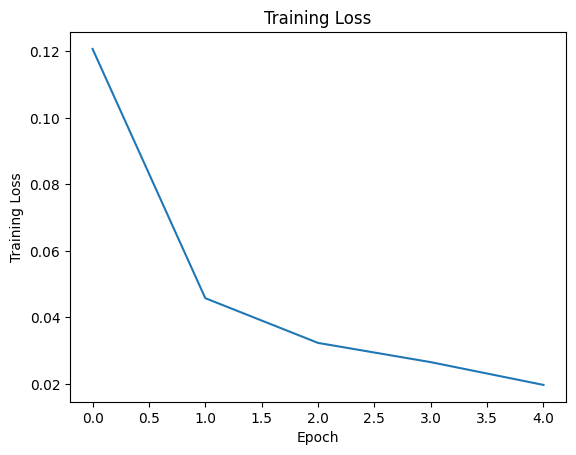

In [ ]:
plt.plot(train_losses)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Training Loss")

plt.show()

In [ ]:
model.eval()

CNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (classifier): Sequential(
    (0): Linear(in_features=1568, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [ ]:
correct = 0
total = 0

In [ ]:
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        total += labels.size(0)

        correct += (
            predictions == labels
        ).sum().item()

In [ ]:
accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

In [ ]:
all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.numpy()
        )

In [ ]:
cm = confusion_matrix(
    all_labels,
    all_predictions
)


In [ ]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(range(10))
)

disp.plot()

plt.title("MNIST Confusion Matrix")
plt.show()

In [ ]:
print(
    classification_report(
        all_labels,
        all_predictions,
        digits=4
    )
)